# 02 — Exploratory analysis

**Question for this notebook:** what do the earthquake rate and the ground uplift look like over time, and how do they relate? This is looking before modelling. It does not measure forecasting skill: that comes in phase 7, with time-ordered splits.

**Plan:**
1. Event rate over time. *(this step)*
2. Uplift and uplift rate over time.
3. Uplift against cumulative event count (the paper's central relationship).
4. Event rate against uplift rate, including lags.
5. The M ≥ 3 events.
6. Map of events and GPS stations.

Throughout, "M ≥ 0.6" means events with Md (binned to 0.1) of at least `MC_MAIN` = 0.6, the magnitude of completeness chosen in `01_completeness`. Counts above Mc are comparable across years; counts of *all* events partly track the growth of the seismic network.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.completeness import MC_MAIN
from src.series import event_counts, period_start, station_daily, trailing_rate

events = pd.read_parquet("../data/processed/catalogue.parquet")
gps = pd.read_parquet("../data/processed/gps_daily.parquet")

# The last weeks of the catalogue are incomplete: the final bulletin lags a few weeks
# (see CLAUDE.md). Shade them on plots; leave them out of anything quantitative.
INCOMPLETE_FROM = pd.Timestamp("2026-09-01", tz="UTC")
print(f"Events: {events['time'].min():%Y-%m-%d} to {events['time'].max():%Y-%m-%d}")
print(f"GPS:    {gps['date'].min():%Y-%m-%d} to {gps['date'].max():%Y-%m-%d}")

Events: 2005-03-22 to 2026-10-21
GPS:    2000-01-01 to 2025-12-31


## 1. Event rate over time

Monthly event counts, for all events and for M ≥ 0.6, on a log scale. Months with no events can't be drawn on a log scale, so they show as gaps. (Weekly counts, which the targets will use, are summarised in the table below.)

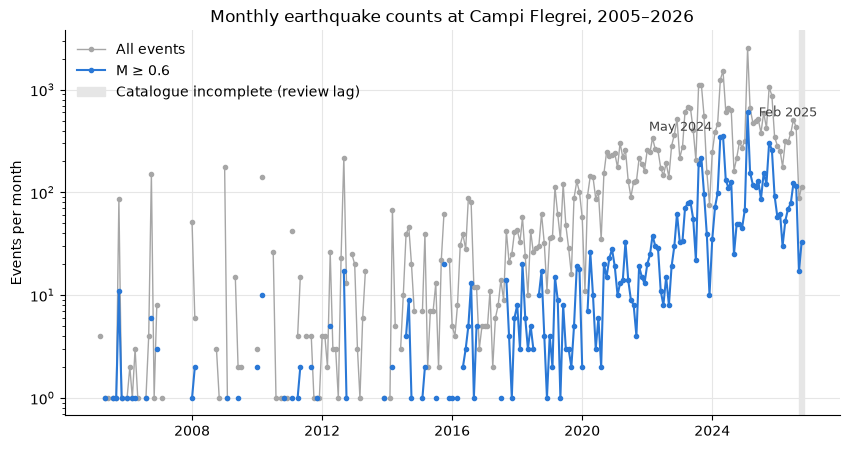

In [2]:
monthly_all = event_counts(events, "M", start="2005-01-01", end="2026-10-21")
monthly_mc = event_counts(events, "M", mc=MC_MAIN, start="2005-01-01", end="2026-10-21")
weekly_mc = event_counts(events, "W", mc=MC_MAIN, start="2005-01-03", end="2026-10-21")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly_all.index, monthly_all.where(monthly_all > 0), marker="o", markersize=3,
        linewidth=1, color="0.65", label="All events")
ax.plot(monthly_mc.index, monthly_mc.where(monthly_mc > 0), marker="o", markersize=3,
        linewidth=1.5, color="#2a78d6", label=f"M ≥ {MC_MAIN}")
ax.axvspan(INCOMPLETE_FROM, monthly_all.index[-1] + pd.Timedelta(days=31), color="0.9",
           label="Catalogue incomplete (review lag)")

# Label two of the busiest swarms (placed by hand so the labels don't collide).
for month, offset in [("2025-02-01", (8, 0)), ("2024-05-01", (-8, 6))]:
    month = pd.Timestamp(month, tz="UTC")
    ax.annotate(f"{month:%b %Y}", (month, monthly_mc[month]), textcoords="offset points",
                xytext=offset, ha="left" if offset[0] > 0 else "right", va="center",
                fontsize=9, color="0.25")

ax.set_yscale("log")
ax.set_ylabel("Events per month")
ax.set_title("Monthly earthquake counts at Campi Flegrei, 2005–2026")
ax.grid(True, which="major", color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

How often is a week empty? This matters for the weekly-count target in phase 6: a series that is almost all zeros behaves very differently from one with tens of events a week.

In [3]:
complete = weekly_mc[weekly_mc.index < INCOMPLETE_FROM]
by_year = complete.groupby(complete.index.year).agg(
    weeks="size",
    events="sum",
    share_of_weeks_with_none=lambda s: (s == 0).mean(),
    median_per_week="median",
    max_per_week="max",
)
by_year.round(2)

,weeks,events,share_of_weeks_with_none,median_per_week,max_per_week
period_start,,,,,
2005,52,15,0.90,0.0,11
2006,52,13,0.88,0.0,6
2007,53,1,0.98,0.0,1
2008,52,2,0.96,0.0,1
2009,52,2,0.96,0.0,1
2010,52,13,0.94,0.0,10
2011,52,7,0.90,0.0,2
2012,53,23,0.91,0.0,13
2013,52,1,0.98,0.0,1


**What plot 1 shows:**

- **Two regimes.** Until about 2016, events with M ≥ 0.6 are rare: most months have none or one, with occasional short bursts (for example late 2005, 2012). From 2017–2018 the rate climbs steadily, from about 7 a month in 2018 to about 180 a month in 2025: roughly a doubling every 1.5 years, a straight-ish line on the log scale.
- **Swarms on top of the trend.** The busiest months are swarms around the larger earthquakes: May 2024 (the Md 4.4) and February 2025 (600 events at M ≥ 0.6 in one month).
- **2026 is quieter than 2025** (about 17 events a week at M ≥ 0.6 against 42), even before the incomplete last weeks (shaded).
- **For the weekly target (phase 6):** before 2018, 73–98% of weeks have no event at M ≥ 0.6; from 2023 almost every week has some, with a median of 10–27. A model has to handle both: a count model that allows many zeros (Poisson or negative binomial), and an evaluation that reports early and recent years separately. We may decide to train only from about 2018, where there is enough signal; that's a phase 6 decision.

## 2. Uplift and uplift rate over time

**Which stations have data when?** The 21 GPS stations started in different years. The chart shows, for each month, the share of days with a GPS solution. Stations are sorted by how much they rose from January 2018 to the end of their record, a rough proxy for distance from the centre of uplift at Pozzuoli.

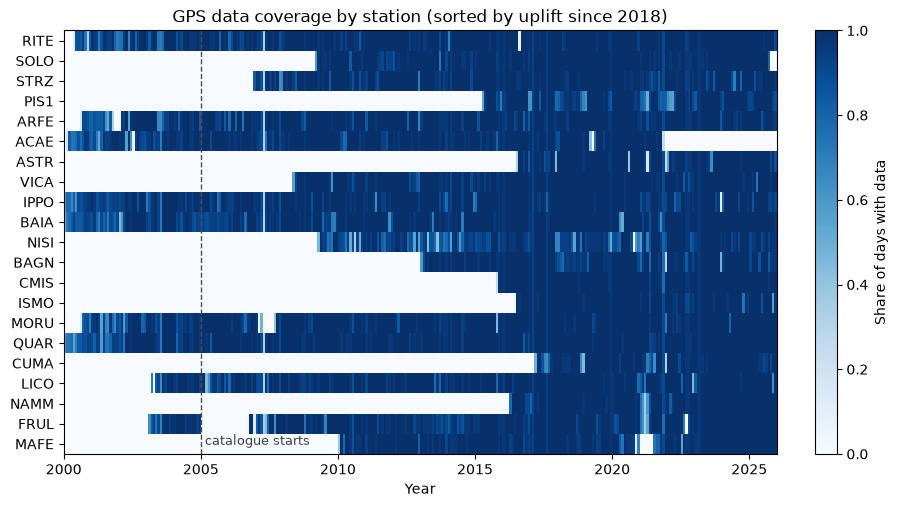

In [4]:
uplift_since_2018 = (
    gps.sort_values("date").groupby("station", observed=True)["up"].last()
    - gps[(gps["date"] >= "2018-01-01") & (gps["date"] < "2018-02-01")]
      .groupby("station", observed=True)["up"].mean()
)
order = uplift_since_2018.sort_values(ascending=False).index.tolist()

months = pd.date_range("2000-01-01", "2025-12-01", freq="MS", tz="UTC")
coverage = (
    gps.assign(month=period_start(gps["date"], "M"))
    .groupby(["station", "month"], observed=True).size()
    .unstack("month").reindex(index=order, columns=months).fillna(0)
    / months.days_in_month.values
)

fig, ax = plt.subplots(figsize=(10, 5.5))
image = ax.imshow(coverage.values, aspect="auto", cmap="Blues", vmin=0, vmax=1,
                  extent=[months[0].year, months[-1].year + 1, len(order), 0],
                  interpolation="nearest")
ax.set_yticks(np.arange(len(order)) + 0.5, order)
ax.axvline(2005, color="0.3", linewidth=1, linestyle="--")
ax.text(2005.15, len(order) - 0.3, "catalogue starts", fontsize=9, color="0.25", va="bottom")
ax.set_xlabel("Year")
ax.set_title("GPS data coverage by station (sorted by uplift since 2018)")
fig.colorbar(image, ax=ax, label="Share of days with data", fraction=0.03)
plt.show()

**Uplift and its rate.** Five stations with long records, from the centre outwards: RITE (Pozzuoli, the largest uplift), ARFE, IPPO, QUAR and LICO (far away). Positions are vertical displacement relative to each station's mean in January 2005, when the catalogue starts.

The rate is the slope of a straight line fitted to the previous 90 days (`trailing_rate`). Daily GPS heights are too noisy (about ±10 mm) to difference day by day. The window is *trailing*: each day's rate uses only data up to that day, so the same function can later give forecasting features without looking into the future.

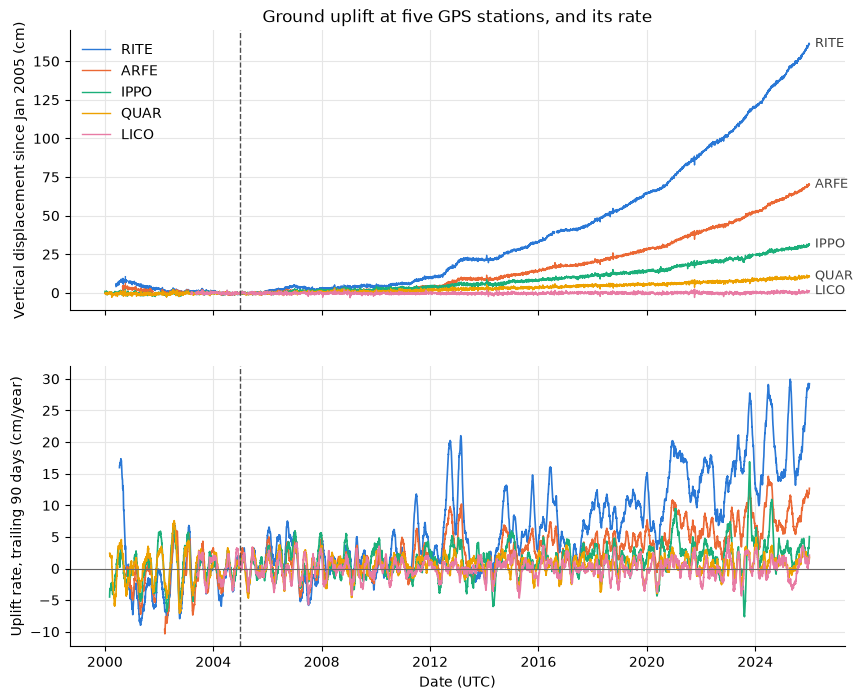

In [5]:
stations = ["RITE", "ARFE", "IPPO", "QUAR", "LICO"]
station_colours = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

fig, (ax_up, ax_rate) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for station, colour in zip(stations, station_colours):
    up = station_daily(gps, station)
    up_cm = (up - up["2005-01"].mean()) * 100
    ax_up.plot(up_cm.index, up_cm, linewidth=1, color=colour, label=station)
    ax_up.annotate(station, (up_cm.dropna().index[-1], up_cm.dropna().iloc[-1]),
                   textcoords="offset points", xytext=(4, 0), va="center", fontsize=9, color="0.25")
    ax_rate.plot(up.index, trailing_rate(up, 90) * 100, linewidth=1.2, color=colour, label=station)

ax_up.set_ylabel("Vertical displacement since Jan 2005 (cm)")
ax_up.set_title("Ground uplift at five GPS stations, and its rate")
ax_up.legend(frameon=False, loc="upper left")
ax_rate.axhline(0, color="0.4", linewidth=0.8)
ax_rate.set_ylabel("Uplift rate, trailing 90 days (cm/year)")
ax_rate.set_xlabel("Date (UTC)")
for ax in (ax_up, ax_rate):
    ax.axvline(pd.Timestamp("2005-01-01", tz="UTC"), color="0.3", linewidth=1, linestyle="--")
    ax.grid(True, which="major", color="0.9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

**The same uplift on a logarithmic scale.** On a log scale, steady *exponential* growth is a straight line, and the slope gives the doubling time. Displacements at or below 1 cm are left out: they are within GPS noise, and zero or negative values can't be shown on a log scale. LICO is left out because it barely moves.

*Caveat:* the "zero" here is each station's position in January 2005, which is an arbitrary choice. A different start date shifts all values and bends the early part of the curve, so only the later, larger part of each curve is meaningful on this scale.

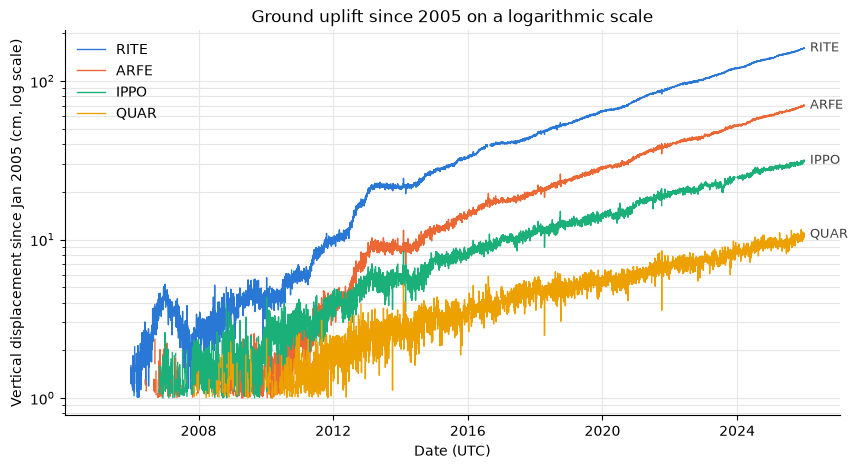

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
for station, colour in zip(stations[:4], station_colours[:4]):
    up = station_daily(gps, station)
    up_cm = (up - up["2005-01"].mean()) * 100
    up_cm = up_cm["2005":].where(up_cm > 1)
    ax.plot(up_cm.index, up_cm, linewidth=1, color=colour, label=station)
    last = up_cm.dropna()
    ax.annotate(station, (last.index[-1], last.iloc[-1]), textcoords="offset points",
                xytext=(4, 0), va="center", fontsize=9, color="0.25")

ax.set_yscale("log")
ax.set_ylabel("Vertical displacement since Jan 2005 (cm, log scale)")
ax.set_xlabel("Date (UTC)")
ax.set_title("Ground uplift since 2005 on a logarithmic scale")
ax.grid(True, which="both", color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

In [7]:
# Doubling time of RITE's uplift: fit a straight line to log(uplift) over several periods.
rite = station_daily(gps, "RITE")
rite_cm = ((rite - rite["2005-01"].mean()) * 100).dropna()
rows = {}
for start, end in [("2012", "2025"), ("2012", "2017"), ("2018", "2021"), ("2022", "2025")]:
    part = rite_cm[start:end]
    years = (part.index - part.index[0]).days / 365.25
    slope = np.polyfit(years, np.log(part.values), 1)[0]  # growth rate per year (natural log)
    rows[f"{start}–{end}"] = {"uplift at start (cm)": round(part.iloc[:30].mean(), 1),
                              "uplift at end (cm)": round(part.iloc[-30:].mean(), 1),
                              "doubling time (years)": round(np.log(2) / slope, 1)}
pd.DataFrame(rows).T

,uplift at start (cm),uplift at end (cm),doubling time (years)
2012–2025,10.0,160.2,4.0
2012–2017,10.0,45.2,3.1
2018–2021,45.9,89.3,4.2
2022–2025,90.7,160.2,4.7


**What the log plot shows:**

- **From about 2013 the curves are close to straight lines: the uplift grows roughly exponentially.** At RITE it doubled about every 4 years from 2012 to 2025 (10 cm to 160 cm).
- **The doubling time is slowly getting longer:** about 3 years in 2012–2017, 4.2 in 2018–2021 and 4.7 in 2022–2025. So the growth is now a little slower than exponential, even though the uplift rate in cm/year is still rising.
- **The stations run roughly parallel** from 2013 on: they grow by about the same factor, with RITE (160 cm by 2025) about 2.3 times ARFE, 5 times IPPO and 15 times QUAR. That fits one source whose shape stays the same while its strength grows. It also suggests that for forecasting, several stations may carry largely the same information as RITE alone, apart from noise.
- **2012–2013 stands out** as a fast step at RITE, ARFE and IPPO, and before about 2011 the curves are mostly noise (uplift of only a few cm).

The exponential look depends on the January 2005 zero point (see caveat above), so these doubling times describe this choice of reference, not a physical constant.

In [8]:
# Uplift rate at RITE by year (cm/year): mean of the daily 90-day rates.
rite_rate = trailing_rate(station_daily(gps, "RITE"), 90) * 100
rite_rate["2005":].groupby(rite_rate["2005":].index.year).mean().round(1).rename("RITE cm/year").to_frame()

,RITE cm/year
date,
2005,0.6
2006,3.8
2007,-1.7
2008,1.2
2009,0.7
2010,1.7
2011,3.8
2012,7.4
2013,4.4


**What plot 2 shows:**

- **Coverage.** Only 9 stations have data from before 2005: seven since 2000 (RITE, ARFE, ACAE, IPPO, BAIA, MORU, QUAR) and LICO and FRUL since 2003. The other 12 start between 2006 and 2017. ACAE stops in November 2021 and SOLO in September 2025; FRUL has a gap in 2005–2006 and MAFE one in 2021. So any feature that uses *all 21 stations* only exists from 2017; before that, features must rely on the long-record stations, or handle missing stations.
- **Uplift accelerates.** RITE rose about 160 cm since January 2005, almost all of it after 2011. Its rate climbs from near zero in 2005–2010 to about 10 cm/year in 2018–2020 and about 18–21 cm/year in 2023–2025 (table). Other stations follow the same shape, scaled down with distance: ARFE about 70 cm, IPPO 30, QUAR 10, LICO almost nothing. That common shape is expected if one source under Pozzuoli drives all of them.
- **The rate comes in pulses**, not as a smooth curve: at RITE there are bursts to 20–30 cm/year in 2012–2013, 2020–2021 and repeatedly in 2023–2025. Whether those pulses line up with seismic swarms is the question for plot 4.
- **Noise.** At far stations the 90-day rate wobbles by about ±5 cm/year around zero, with similar wiggles at all stations in the early years (probably seasonal or network-wide effects). So rates from far stations carry little signal on their own; differences between stations, or a longer window, may help. That's a feature-engineering question for phase 6.